In [ ]:
print("hello") #updated test

hello


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#since we don't need to extract

!cp "/content/drive/MyDrive/Kennydataset_SCF_v2.h5" /content/
!cp "/content/drive/MyDrive/Kennydataset_IQ_v2.h5" /content/

'''
# getting data
!cp /content/drive/MyDrive/RadioMLDataset2018.zip /content/
!unzip -q /content/RadioMLDataset2018.zip -d /content/data/
'''

Mounted at /content/drive


'\n# getting data\n!cp /content/drive/MyDrive/RadioMLDataset2018.zip /content/\n!unzip -q /content/RadioMLDataset2018.zip -d /content/data/\n'

In [ ]:
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

torch.backends.cudnn.benchmark = True


device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # basically only using gpu when available
print(f"using device - {device}")

from torch.amp import autocast, GradScaler
scaler = GradScaler(device = 'cuda')


using device - cuda


In [ ]:
import os

save_dir = "/content/drive/MyDrive/RadioML_Models"
os.makedirs(save_dir, exist_ok=True)

model_save_path = os.path.join(save_dir, "HybridGatedInitial.pth")

# get rid previous checkpoint so training starts fresh if needed
if os.path.exists(model_save_path):
    os.remove(model_save_path)
    print("Removed old checkpoint. Starting fresh training.")

In [ ]:
print(os.cpu_count())

12


In [ ]:
#!df -h /dev/shm

### Loading the HDF5 Dataset

The dataset is stored in an HDF5 file, which is a common format for storing large amounts of numerical data. We'll use the `h5py` library to open this file and load the IQ samples (X), one-hot encoded class labels (Y), and Signal-to-Noise Ratio (SNR) values (Z).

In [ ]:
#!find /content/drive/MyDrive -name "*.h5"

In [ ]:
iq_path = "/content/drive/MyDrive/Kennydataset_IQ_v2.h5"
scf_path = "/content/drive/MyDrive/Kennydataset_SCF_v2.h5"

hdf5_file = h5py.File(scf_path, 'r')
iq_file = h5py.File(iq_path, 'r')

# X = hdf5_file["X_scf"] # - IQ samples
Y = hdf5_file["Y"] # - one hot class labels
Z = hdf5_file["Z"] # - SNR values

print("SCF file keys:", list(hdf5_file.keys()))
print("I/Q file keys:", list(iq_file.keys()))

SCF file keys: ['X_scf', 'X_scf_conj', 'Y', 'Z', 'alpha_axis_hz', 'f_axis_hz', 'imp']
I/Q file keys: ['X_iq', 'Y', 'Z', 'imp']


In [ ]:
# print(f"X shape: {X.shape}")   # signals
print(f"Y shape: {Y.shape}")   # labels
print(f"Z shape: {Z.shape}")   # SNR
print(f"SNR range: {np.unique(Z)}")
print(f"Number of classes: {Y.shape[1]}")

Y shape: (346112, 13)
Z shape: (346112, 1)
SNR range: [-20. -18. -16. -14. -12. -10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.
   8.  10.  12.  14.  16.  18.  20.  22.  24.  26.  28.  30.]
Number of classes: 13


In [ ]:
# X into memory
print("Loading SCF")
X_loaded = hdf5_file["X_scf"][:]   #.astype(np.float32).transpose(0, 2, 1)
print("Loading IQ")
X_iq = iq_file["X_iq"][:].astype(np.float32, copy = False).transpose(0, 2, 1)

print(f" SCF shape: {X_loaded.shape} && dtype: {X_loaded.dtype}")
print(f" IQ shape: {X_iq.shape} && dtype: {X_iq.dtype}")

Loading SCF
Loading IQ
 SCF shape: (346112, 128, 128) && dtype: float32
 IQ shape: (346112, 2, 4096) && dtype: float32


In [ ]:
MOD_LABELS = [
    "BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "PAM4", "GFSK",
    "CPFSK", "2FSK", "4FSK", "B-FM", "AM-DSB", "AM-SSB"
]

labels = np.argmax(Y[:], axis = 1)
snrs = Z[:, 0].astype(int)

# rand seed yeeehawww
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"Total samples - {len(labels):,}")
print(f"Classes       - {len(MOD_LABELS)}")
print(f"SNR levels    - {sorted(np.unique(snrs).tolist())}")

Total samples - 346,112
Classes       - 13
SNR levels    - [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]


In [ ]:
# Can remove once confirmed - this is just a test anyaway
imp_scf = hdf5_file["imp"][:]
imp_iq = iq_file["imp"][:]

print("Impairments identical row by row:", np.array_equal(imp_scf, imp_iq))
print("Labels identical:", np.array_equal(hdf5_file["Y"][:], iq_file["Y"][:]))
print("SNRs identical:", np.array_equal(hdf5_file["Z"][:], iq_file["Z"][:]))

Impairments identical row by row: True
Labels identical: True
SNRs identical: True


In [ ]:
print("Unique label idx:", np.unique(labels))
print("Num unique labels:", len(np.unique(labels)))

for i, mod in enumerate(MOD_LABELS):
    print(f"{i:2d}: {mod}")

Unique label idx: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Num unique labels: 13
 0: BPSK
 1: QPSK
 2: 8PSK
 3: 16QAM
 4: 64QAM
 5: PAM4
 6: GFSK
 7: CPFSK
 8: 2FSK
 9: 4FSK
10: B-FM
11: AM-DSB
12: AM-SSB


In [ ]:
# Dataset

class HybridDataset(Dataset):
    def __init__(self, X_iq, X_scf, labels, snrs, indices, iq_mean, iq_std, scf_mean, scf_std):
        self.X_iq = X_iq
        self.X_scf = X_scf
        self.labels = labels[indices]
        self.snrs = snrs[indices]
        self.indices = indices
        self.iq_mean = iq_mean
        self.iq_std = iq_std
        self.scf_mean = scf_mean
        self.scf_std = scf_std

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        i = self.indices[idx]

        iq = self.X_iq[i]
        iq = (iq - self.iq_mean) / (self.iq_std + 1e-6)
        iq = torch.from_numpy(np.ascontiguousarray(iq, dtype = np.float32)) # (2, 4096)

        scf = self.X_scf[i] # already float32 in [0, 1]
        scf = (scf - self.scf_mean) / (self.scf_std + 1e-6)
        scf = torch.from_numpy(np.ascontiguousarray(scf, dtype = np.float32)).unsqueeze(0) # (1, 128, 128)

        label = torch.tensor(self.labels[idx], dtype = torch.long)
        snr = self.snrs[idx]
        return iq, scf, label, snr


ONLY RUN BELOW WITH GPU WIHT HIGH LEVEL SYS RAM TOO

In [ ]:
# trying filtering for snr first - ttraining on the higher so the model isn't completely trash
from sklearn.model_selection import train_test_split

# Keep only samples above the SNR threshold
snr_threshold = -20
valid_indices = np.where(snrs >= snr_threshold)[0]

print(f"Using {len(valid_indices):,} samples with SNR >= {snr_threshold} dB")

BATCH_SIZE = 256

# splitting for both modulation and snr

stratify_labels = np.array([
    f"{labels[i]}_{snrs[i]}"
    for i in valid_indices
])

train_idx, temp_idx = train_test_split(
    valid_indices,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    stratify=stratify_labels
)

temp_strat = np.array([
    f"{labels[i]}_{snrs[i]}"
    for i in temp_idx
])

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    stratify=temp_strat
)

sub = np.random.choice(train_idx, size = 20000, replace = False)

scf_sub = X_loaded[sub]
global_mean = np.float32(scf_sub.mean())
global_std = np.float32(scf_sub.std())
del scf_sub

iq_sub = X_iq[sub]      # same 20,000 training frames
iq_mean = np.float32(iq_sub.mean())
iq_std = np.float32(iq_sub.std())
del iq_sub

print(f"SCF mean={global_mean:.6f}  std={global_std:.6f}")
print(f"I/Q mean={iq_mean:.6f}  std={iq_std:.6f}")

train_data = HybridDataset(X_iq, X_loaded, labels, snrs, train_idx, iq_mean, iq_std, global_mean, global_std)
val_data = HybridDataset(X_iq, X_loaded, labels, snrs, val_idx, iq_mean, iq_std, global_mean, global_std)
test_data = HybridDataset(X_iq, X_loaded, labels, snrs, test_idx, iq_mean, iq_std, global_mean, global_std)

train_loader = DataLoader(train_data, batch_size = BATCH_SIZE, shuffle = True, num_workers = 12,
                          pin_memory = True, prefetch_factor = 2, persistent_workers = True)
val_loader = DataLoader(val_data, batch_size = BATCH_SIZE, shuffle = False, num_workers = 12,
                        pin_memory = True, prefetch_factor = 2, persistent_workers = True)
test_loader = DataLoader(test_data, batch_size = BATCH_SIZE, shuffle = False, num_workers = 12,
                         pin_memory = True, prefetch_factor = 2, persistent_workers = True)

print(f"Train samples : {len(train_data):,}")
print(f"Val samples   : {len(val_data):,}")
print(f"Test samples  : {len(test_data):,}")
print(test_idx[:10], test_idx.sum())

Using 346,112 samples with SNR >= -20 dB
SCF mean=0.403967  std=0.284927
I/Q mean=0.000040  std=2.410887
Train samples : 242,278
Val samples   : 51,917
Test samples  : 51,917
[106249  74854  27735 311335 127011  58273 244756 109436 184920  66678] 9026026435


In [ ]:
print(np.min(snrs[train_idx]), np.max(snrs[train_idx]))

-20 30


In [ ]:
# write here and pretend you know what you're doing

# since SCF we are now going to changee 1 to 2 D and stuff
class ResBlock1D(nn.Module):
    def __init__(self, channels, kernel_size = 3):
        super(ResBlock1D, self).__init__()
        self.conv1 = nn.Conv1d(channels, channels, kernel_size = kernel_size, padding = kernel_size // 2)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size = kernel_size, padding = kernel_size // 2)
        self.bn2 = nn.BatchNorm1d(channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + residual)


class ResBlock2D(nn.Module):
    def __init__(self, channels, kernel_size = 3):
        super(ResBlock2D, self).__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size = kernel_size, padding = kernel_size // 2)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size = kernel_size, padding = kernel_size // 2)
        self.bn2 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + residual)


class IQBranch(nn.Module):
    # same layer names as the standalone raw I/Q CNNModel
    def __init__(self, num_classes = 13):
        super(IQBranch, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(2, 64, kernel_size = 7, padding = 3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
        )
        self.stage1 = nn.Sequential(ResBlock1D(64), ResBlock1D(64), nn.MaxPool1d(2))
        self.stage2 = nn.Sequential(nn.Conv1d(64, 128, 1), ResBlock1D(128), ResBlock1D(128), nn.MaxPool1d(2))
        self.stage3 = nn.Sequential(nn.Conv1d(128, 256, 1), ResBlock1D(256), ResBlock1D(256), nn.MaxPool1d(2))
        self.stage4 = nn.MaxPool1d(2)
        self.pool = nn.AdaptiveAvgPool1d(4)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)

        x = self.classifier[0](x)    # flatten
        x = self.classifier[1](x)    # linear 1024 -> 256
        x = self.classifier[2](x)    # relu
        hidden = x                   # the 256-number summary that goes to the gate

        x = self.classifier[3](x)    # dropout
        logits = self.classifier[4](x)    # this branch's own prediction (auxiliary head)
        return hidden, logits


SCF_STRIDE = 2

class SCFBranch(nn.Module):
    # same layer names as the standalone SCF CNNModel because yea!
    def __init__(self, num_classes = 13):
        super(SCFBranch, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size = 7, stride = SCF_STRIDE, padding = 3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
        )
        self.stage1 = nn.Sequential(ResBlock2D(64), ResBlock2D(64), nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(nn.Conv2d(64, 128, 1), ResBlock2D(128), ResBlock2D(128), nn.MaxPool2d(2))
        self.stage3 = nn.Sequential(nn.Conv2d(128, 256, 1), ResBlock2D(256), ResBlock2D(256), nn.MaxPool2d(2))
        self.pool = nn.AdaptiveAvgPool2d(4)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x)

        x = self.classifier[0](x)
        x = self.classifier[1](x)
        x = self.classifier[2](x)
        hidden = x

        x = self.classifier[3](x)
        logits = self.classifier[4](x)
        return hidden, logits


class HybridGatedCNN(nn.Module):
    def __init__(self, num_classes = 13):
        super(HybridGatedCNN, self).__init__()
        self.iq_branch = IQBranch(num_classes)
        self.scf_branch = SCFBranch(num_classes)

        # puts both summaries on the same scale. Therefore like basically a gate of 0.7 really means "70% I/Q"
        self.iq_norm = nn.LayerNorm(256)
        self.scf_norm = nn.LayerNorm(256)

        # reads both summaries, outputs one number per frame between 0 and 1
        self.gate = nn.Sequential(
            nn.Linear(512, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

        self.fused_dropout = nn.Dropout(0.4)
        self.fused_head = nn.Linear(256, num_classes)

    def forward(self, iq, scf):
        iq_hidden, iq_logits = self.iq_branch(iq)
        scf_hidden, scf_logits = self.scf_branch(scf)

        iq_hidden = self.iq_norm(iq_hidden)
        scf_hidden = self.scf_norm(scf_hidden)

        both = torch.cat([iq_hidden, scf_hidden], dim = 1)
        g = self.gate(both)                  # (batch, 1): 1 = all I/Q, 0 = all SCF

        fused = g * iq_hidden + (1 - g) * scf_hidden
        fused = self.fused_dropout(fused)
        fused_logits = self.fused_head(fused)

        return fused_logits, iq_logits, scf_logits, g

In [ ]:
NUM_CLASSES = 13

model = HybridGatedCNN(num_classes = NUM_CLASSES).to(device)

iq_b, scf_b, lab_b, snr_b = next(iter(train_loader))
iq_b = iq_b.to(device)
scf_b = scf_b.to(device)

with torch.no_grad():
    fused_logits, iq_logits, scf_logits, gate = model(iq_b, scf_b)

print(f"I/Q input: {iq_b.shape}") # [256, 2, 4096]
print(f"SCF input: {scf_b.shape}") # [256, 1, 128, 128]
print(f"Fused output: {fused_logits.shape}") # [256, 13]
print(f"Gate: {gate.shape}, mean {gate.mean().item():.3f}")    # [256, 1], near 0.5 before training
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

I/Q input: torch.Size([256, 2, 4096])
SCF input: torch.Size([256, 1, 128, 128])
Fused output: torch.Size([256, 13])
Gate: torch.Size([256, 1]), mean 0.494
Model parameters: 5,581,800


In [ ]:

epochs = 200
AUX_WEIGHT = 0.5     # how much each branch's own loss counts, relative to the fused loss

criterion = nn.CrossEntropyLoss(label_smoothing = 0.05)

fusion_params = (list(model.iq_norm.parameters()) + list(model.scf_norm.parameters())
                 + list(model.gate.parameters()) + list(model.fused_head.parameters()))

optimiser = optim.AdamW([
    {"params": model.iq_branch.parameters(), "lr": 3e-4},
    {"params": model.scf_branch.parameters(), "lr": 1e-4},
    {"params": fusion_params, "lr": 3e-4},
], weight_decay = 1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max = epochs, eta_min = 1e-6)

print("Optimiser : AdamW, per-branch learning rates")
print("LR (I/Q/SCF/fusion) : 3e-4 / 1e-4 / 3e-4")
print(f"Aux loss weight : {AUX_WEIGHT}")
print(f"Epochs: {epochs}")

Optimiser : AdamW, per-branch learning rates
LR (I/Q/SCF/fusion) : 3e-4 / 1e-4 / 3e-4
Aux loss weight : 0.5
Epochs: 200


In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimiser, scheduler, num_epochs):
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    best_val_acc = 0.0
    patience = 10
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        # training
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for batch_idx, (iq_batch, scf_batch, labels_batch, _) in enumerate(train_loader):
            iq_batch = iq_batch.to(device)
            scf_batch = scf_batch.to(device)
            labels_batch = labels_batch.to(device)

            optimiser.zero_grad()
            with autocast(device_type = 'cuda', dtype = torch.bfloat16):
                fused_logits, iq_logits, scf_logits, gate = model(iq_batch, scf_batch)
                loss_fused = criterion(fused_logits, labels_batch)
                loss_iq = criterion(iq_logits, labels_batch)
                loss_scf = criterion(scf_logits, labels_batch)
                loss = loss_fused + AUX_WEIGHT * (loss_iq + loss_scf)

            scaler.scale(loss).backward()
            scaler.step(optimiser)
            scaler.update()

            running_loss += loss.item()
            preds = fused_logits.argmax(dim = 1)
            running_correct += (preds == labels_batch).sum().item()
            running_total += labels_batch.size(0)

            if (batch_idx + 1) % 200 == 0:
                print(f"  Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)} "
                      f"| Loss: {running_loss/(batch_idx+1):.4f}")

        train_loss = running_loss / len(train_loader)
        train_acc = running_correct / running_total

        # validation - fused output only, since that's the hybrid's actual prediction
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        gate_sum = 0.0

        with torch.no_grad():
            for iq_batch, scf_batch, labels_batch, _ in val_loader:
                iq_batch = iq_batch.to(device)
                scf_batch = scf_batch.to(device)
                labels_batch = labels_batch.to(device)

                fused_logits, iq_logits, scf_logits, gate = model(iq_batch, scf_batch)
                loss = criterion(fused_logits, labels_batch)
                val_loss += loss.item()

                preds = fused_logits.argmax(dim = 1)
                val_correct += (preds == labels_batch).sum().item()
                val_total += labels_batch.size(0)
                gate_sum += gate.sum().item()

        val_loss = val_loss / len(val_loader)
        val_acc = val_correct / val_total
        mean_gate = gate_sum / val_total

        scheduler.step()
        print(f"LR: {optimiser.param_groups[0]['lr']:.2e} | Mean val gate (1 = I/Q, 0 = SCF): {mean_gate:.3f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            epochs_without_improvement = 0
            torch.save(model.state_dict(), model_save_path)
            print(f"Saved best model at epoch {epoch + 1} (Val Acc: {val_acc*100:.2f} %)")
        else:
            epochs_without_improvement += 1
            print(f"No improvement for {epochs_without_improvement}/{patience} epochs.")

        if epochs_without_improvement >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
            break

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

    return train_losses, val_losses, train_accs, val_accs, best_val_acc

In [ ]:
#### THIS IS THE MAIN TRAINING LOOP - ONLY RUN ONCE ON FPU
train_losses, val_losses, train_accs, val_accs, best_val_acc = train_model(
    model, train_loader, val_loader, criterion, optimiser, scheduler, epochs
)

  Epoch 1 | Batch 200/947 | Loss: 3.3259
  Epoch 1 | Batch 400/947 | Loss: 2.8366
  Epoch 1 | Batch 600/947 | Loss: 2.6188
  Epoch 1 | Batch 800/947 | Loss: 2.4917
LR: 3.00e-04 | Mean val gate (1 = I/Q, 0 = SCF): 0.356
Saved best model at epoch 1 (Val Acc: 69.55 %)
Epoch 1/200 | Train Loss: 2.4253 | Train Acc: 65.80% | Val Loss: 0.9559 | Val Acc: 69.55%
  Epoch 2 | Batch 200/947 | Loss: 2.0427
  Epoch 2 | Batch 400/947 | Loss: 2.0209
  Epoch 2 | Batch 600/947 | Loss: 2.0015
  Epoch 2 | Batch 800/947 | Loss: 1.9907
LR: 3.00e-04 | Mean val gate (1 = I/Q, 0 = SCF): 0.393
Saved best model at epoch 2 (Val Acc: 72.70 %)
Epoch 2/200 | Train Loss: 1.9771 | Train Acc: 73.16% | Val Loss: 0.9242 | Val Acc: 72.70%
  Epoch 3 | Batch 200/947 | Loss: 1.8896
  Epoch 3 | Batch 400/947 | Loss: 1.8787
  Epoch 3 | Batch 600/947 | Loss: 1.8640
  Epoch 3 | Batch 800/947 | Loss: 1.8522
LR: 3.00e-04 | Mean val gate (1 = I/Q, 0 = SCF): 0.427
Saved best model at epoch 3 (Val Acc: 76.52 %)
Epoch 3/200 | Train Lo

In [ ]:
# just in case the loading is messed up
# Load the best model saved
model.load_state_dict(torch.load(model_save_path, map_location=device))
model.to(device)
model.eval()

print("best model mounted and loaded.")
#print(f"Best validation accuracy: {best_val_acc*100:.2f}%")

best model mounted and loaded.


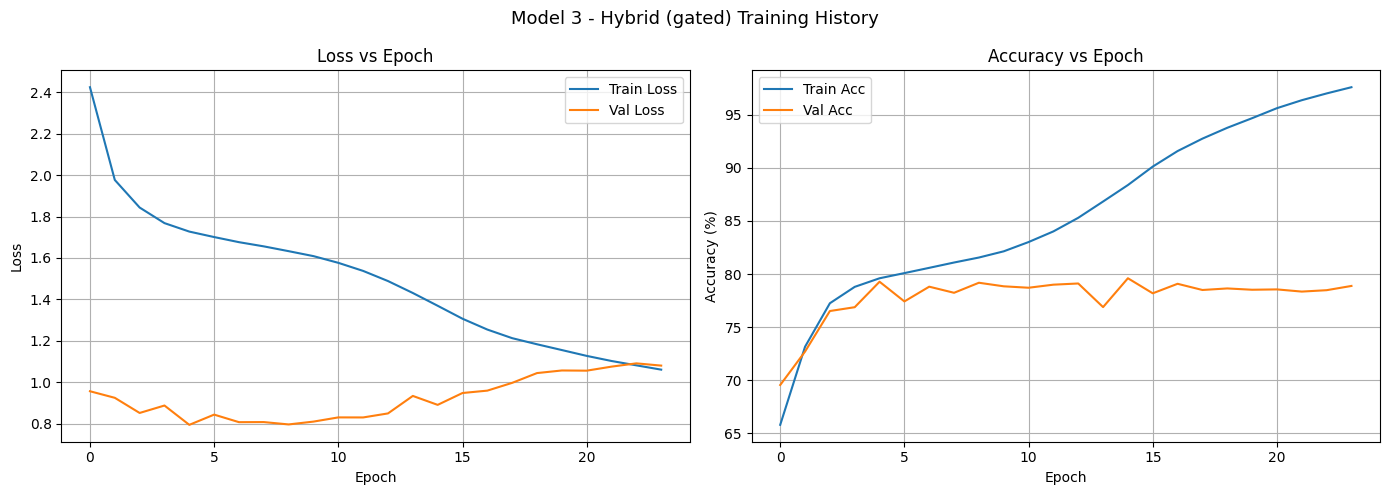

In [ ]:
# Cell 11 - Plot Training History

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses,   label="Val Loss")
ax1.set_title("Loss vs Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

# Accuracy curves
ax2.plot([a*100 for a in train_accs], label="Train Acc")
ax2.plot([a*100 for a in val_accs],   label="Val Acc")
ax2.set_title("Accuracy vs Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True)

plt.suptitle("Model 3 - Hybrid (gated) Training History", fontsize=13)
plt.tight_layout()
plt.show()

# statistical scores you can go.

for evaluation, make sure to use macro f1 instead of f1 - because some modulation types have worse classification ability at the same low snr compared to others type shi

In [ ]:
all_preds = []
all_labels = []
all_snrs = []
all_conf = []
all_true_prob = []
all_entropy = []
all_probs = []
all_gate = []
all_iq_preds = []
all_scf_preds = []

model.eval()
with torch.no_grad():
    for iq_batch, scf_batch, labels_batch, snrs_batch in test_loader:
        iq_batch = iq_batch.to(device)
        scf_batch = scf_batch.to(device)
        labels_dev = labels_batch.to(device)

        fused_logits, iq_logits, scf_logits, gate = model(iq_batch, scf_batch)
        probs = torch.softmax(fused_logits, dim = 1)

        preds = probs.argmax(dim = 1)
        conf = probs.max(dim = 1).values
        true_prob = probs[torch.arange(probs.shape[0]), labels_dev]
        entropy = -(probs * torch.log(probs + 1e-12)).sum(dim = 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels_batch.numpy())
        all_snrs.extend(snrs_batch.numpy())
        all_conf.extend(conf.cpu().numpy())
        all_true_prob.extend(true_prob.cpu().numpy())
        all_entropy.extend(entropy.cpu().numpy())
        all_probs.append(probs.cpu().numpy())
        all_gate.extend(gate[:, 0].cpu().numpy())
        all_iq_preds.extend(iq_logits.argmax(dim = 1).cpu().numpy())
        all_scf_preds.extend(scf_logits.argmax(dim = 1).cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_snrs = np.array(all_snrs)
all_conf = np.array(all_conf)
all_true_prob = np.array(all_true_prob)
all_entropy = np.array(all_entropy)
all_probs = np.concatenate(all_probs, axis = 0)
all_gate = np.array(all_gate)
all_iq_preds = np.array(all_iq_preds)
all_scf_preds = np.array(all_scf_preds)

print("Done. Test samples:", len(all_preds))

Done. Test samples: 51917


In [ ]:
# rebuilding the metrics that the new eval loop no longer computes
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

overall_acc = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average = 'macro')

print(f"Overall Accuracy: {overall_acc*100:.2f}%")
print(f"F1 Score (the macro one) : {macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names = MOD_LABELS, digits = 3))

snr_range = sorted(np.unique(all_snrs).tolist())
snr_accs = {}

for snr in snr_range:
    mask = all_snrs == snr
    snr_acc = accuracy_score(all_labels[mask], all_preds[mask])
    snr_accs[snr] = snr_acc
    print(f"SNR {snr:4d} dB | Acc: {snr_acc*100:.2f}%")

Overall Accuracy: 79.65%
F1 Score (the macro one) : 0.7952

Classification Report:
              precision    recall  f1-score   support

        BPSK      0.715     0.809     0.759      3994
        QPSK      0.725     0.703     0.714      3993
        8PSK      0.790     0.668     0.724      3988
       16QAM      0.656     0.660     0.658      3994
       64QAM      0.749     0.607     0.670      3996
        PAM4      0.700     0.825     0.757      3992
        GFSK      0.765     0.879     0.818      3994
       CPFSK      0.827     0.784     0.805      3995
        2FSK      0.909     0.932     0.920      3996
        4FSK      0.812     0.791     0.801      3994
        B-FM      0.892     0.813     0.851      3992
      AM-DSB      0.927     0.967     0.946      3998
      AM-SSB      0.911     0.917     0.914      3991

    accuracy                          0.797     51917
   macro avg      0.798     0.797     0.795     51917
weighted avg      0.798     0.797     0.795     519

In [ ]:
correct = (all_preds == all_labels)

print(f"Mean confidence (all)     : {all_conf.mean():.3f}")
print(f"Mean confidence (correct) : {all_conf[correct].mean():.3f}")
print(f"Mean confidence (wrong)   : {all_conf[~correct].mean():.3f}")
print(f"Mean prob on true class   : {all_true_prob.mean():.3f}")
print(f"Mean entropy              : {all_entropy.mean():.3f}")
print(f"  ln(6)  = {np.log(6):.3f}  (uncertain across 6 classes)")
print(f"  ln(13) = {np.log(13):.3f}  (no idea at all)")

Mean confidence (all)     : 0.824
Mean confidence (correct) : 0.915
Mean confidence (wrong)   : 0.469
Mean prob on true class   : 0.753
Mean entropy              : 0.602
  ln(6)  = 1.792  (uncertain across 6 classes)
  ln(13) = 2.565  (no idea at all)


In [ ]:
high = (all_snrs >= 20)

print("High SNR only (>= 20 dB)")
print("Class      Acc      Conf    TrueP   Entropy")
for i in range(13):
    mask = (all_labels == i) & high
    acc_i = (all_preds[mask] == all_labels[mask]).mean()
    conf_i = all_conf[mask].mean()
    true_i = all_true_prob[mask].mean()
    ent_i = all_entropy[mask].mean()
    print(f"{MOD_LABELS[i]:8s} {acc_i*100:6.2f}%   {conf_i:.3f}   {true_i:.3f}   {ent_i:.3f}")

High SNR only (>= 20 dB)
Class      Acc      Conf    TrueP   Entropy
BPSK     100.00%   0.963   0.963   0.246
QPSK      99.89%   0.937   0.937   0.358
8PSK      99.78%   0.962   0.960   0.245
16QAM     91.74%   0.897   0.863   0.397
64QAM     95.44%   0.899   0.886   0.429
PAM4     100.00%   0.959   0.959   0.270
GFSK     100.00%   0.957   0.957   0.280
CPFSK    100.00%   0.958   0.958   0.279
2FSK     100.00%   0.955   0.955   0.294
4FSK     100.00%   0.966   0.966   0.234
B-FM     100.00%   0.956   0.956   0.287
AM-DSB   100.00%   0.955   0.955   0.296
AM-SSB   100.00%   0.958   0.958   0.274


In [ ]:
for snr in sorted(np.unique(all_snrs)):
    mask = (all_snrs == snr)
    acc_s = (all_preds[mask] == all_labels[mask]).mean()
    conf_s = all_conf[mask].mean()
    ent_s = all_entropy[mask].mean()
    print(f"SNR {snr:4d} dB | Acc: {acc_s*100:5.2f}% | Conf: {conf_s:.3f} | Entropy: {ent_s:.3f}")

SNR  -20 dB | Acc: 15.52% | Conf: 0.437 | Entropy: 1.669
SNR  -18 dB | Acc: 19.88% | Conf: 0.469 | Entropy: 1.555
SNR  -16 dB | Acc: 27.09% | Conf: 0.511 | Entropy: 1.430
SNR  -14 dB | Acc: 35.35% | Conf: 0.562 | Entropy: 1.282
SNR  -12 dB | Acc: 41.80% | Conf: 0.598 | Entropy: 1.164
SNR  -10 dB | Acc: 52.83% | Conf: 0.648 | Entropy: 1.014
SNR   -8 dB | Acc: 67.23% | Conf: 0.727 | Entropy: 0.793
SNR   -6 dB | Acc: 79.18% | Conf: 0.788 | Entropy: 0.630
SNR   -4 dB | Acc: 83.47% | Conf: 0.826 | Entropy: 0.529
SNR   -2 dB | Acc: 86.33% | Conf: 0.855 | Entropy: 0.479
SNR    0 dB | Acc: 90.67% | Conf: 0.882 | Entropy: 0.433
SNR    2 dB | Acc: 92.69% | Conf: 0.900 | Entropy: 0.398
SNR    4 dB | Acc: 95.64% | Conf: 0.921 | Entropy: 0.354
SNR    6 dB | Acc: 97.50% | Conf: 0.934 | Entropy: 0.328
SNR    8 dB | Acc: 98.45% | Conf: 0.943 | Entropy: 0.307
SNR   10 dB | Acc: 98.70% | Conf: 0.946 | Entropy: 0.301
SNR   12 dB | Acc: 98.65% | Conf: 0.948 | Entropy: 0.297
SNR   14 dB | Acc: 98.80% | Con

In [ ]:
bin_edges = [0.0, 0.2, 0.4, 0.6, 0.8, 1.01]

print("Conf range    n       Accuracy   Mean conf")
for b in range(5):
    lo = bin_edges[b]
    hi = bin_edges[b + 1]
    mask = (all_conf >= lo) & (all_conf < hi)
    n = mask.sum()
    if n > 0:
        print(f"{lo:.1f} - {hi:.1f}   {n:6d}   {correct[mask].mean()*100:6.2f}%    {all_conf[mask].mean():.3f}")

Conf range    n       Accuracy   Mean conf
0.0 - 0.2      458     9.17%    0.180
0.2 - 0.4     5184    15.59%    0.297
0.4 - 0.6     4702    34.11%    0.503
0.6 - 0.8     3221    48.68%    0.694
0.8 - 1.0    38352    97.34%    0.953


CONFUSION OF THE MATRIX BECAUSE THE MATRIX IS CONFUSING

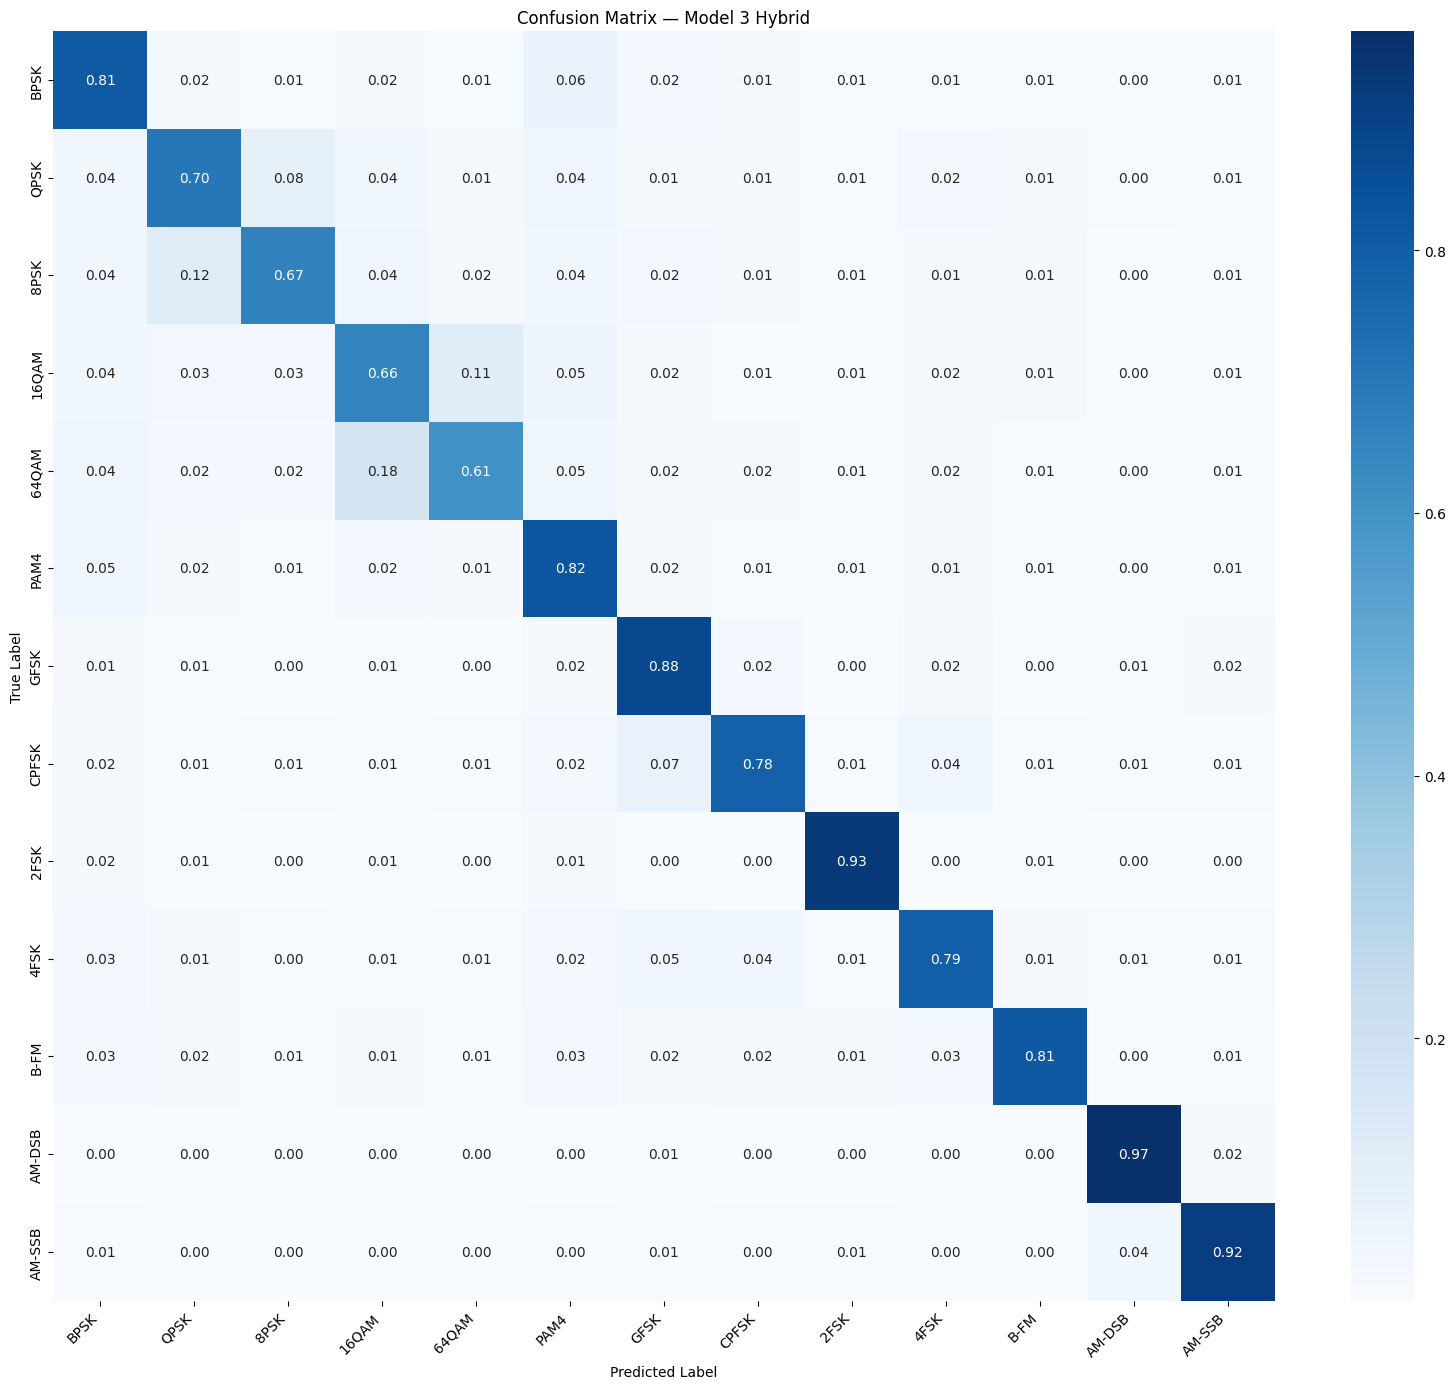

In [ ]:
# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(16, 14))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=MOD_LABELS, yticklabels=MOD_LABELS)
plt.title("Confusion Matrix — Model 3 Hybrid")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

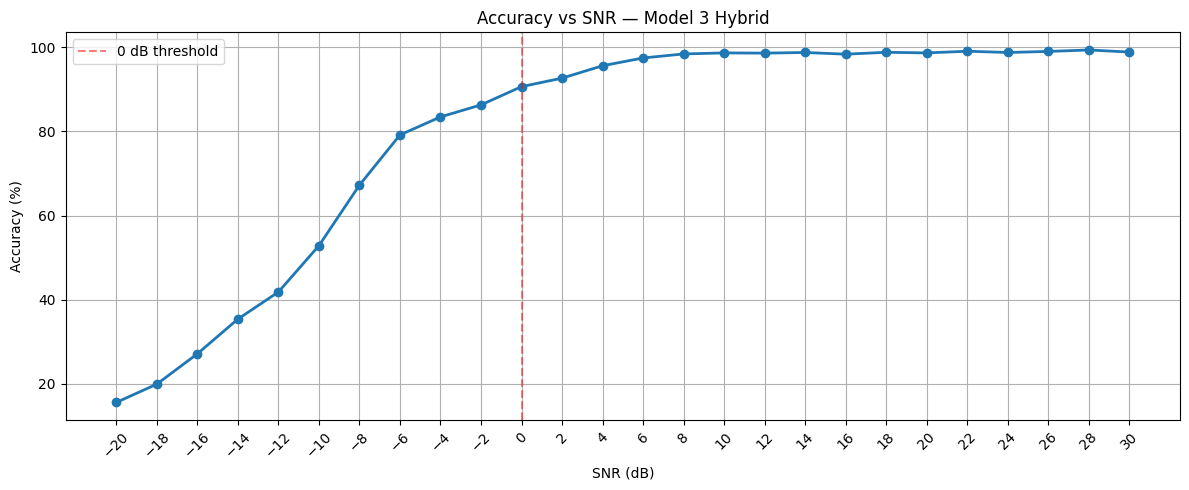

In [ ]:
# Accuracy vs SNR Plot

# x = snr and y is acc -> depend and independent stuff

snrs_sorted = sorted(snr_accs.keys())
accs = [snr_accs[s]*100 for s in snrs_sorted]

plt.figure(figsize=(12, 5))
plt.plot(snrs_sorted, accs, marker='o', linewidth=2)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='0 dB threshold')
plt.title("Accuracy vs SNR — Model 3 Hybrid")
plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.xticks(snrs_sorted, rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

SNR (dB) | Hybrid  | I/Q head | SCF head | Mean gate
     -20 |  15.52% |   16.02% |   14.92% | 0.290
     -18 |  19.88% |   19.58% |   18.78% | 0.282
     -16 |  27.09% |   24.28% |   26.14% | 0.282
     -14 |  35.35% |   29.49% |   33.30% | 0.300
     -12 |  41.80% |   35.45% |   39.25% | 0.343
     -10 |  52.83% |   47.07% |   47.57% | 0.395
      -8 |  67.23% |   60.28% |   61.78% | 0.447
      -6 |  79.18% |   73.82% |   71.82% | 0.466
      -4 |  83.47% |   79.11% |   77.45% | 0.470
      -2 |  86.33% |   84.48% |   80.22% | 0.470
       0 |  90.67% |   89.82% |   82.25% | 0.471
       2 |  92.69% |   92.34% |   82.33% | 0.467
       4 |  95.64% |   95.09% |   83.97% | 0.460
       6 |  97.50% |   97.05% |   83.73% | 0.461
       8 |  98.45% |   98.40% |   83.40% | 0.458
      10 |  98.70% |   98.40% |   83.68% | 0.455
      12 |  98.65% |   98.70% |   83.26% | 0.455
      14 |  98.80% |   98.60% |   83.28% | 0.453
      16 |  98.39% |   98.24% |   83.54% | 0.452
      18 |  98.8

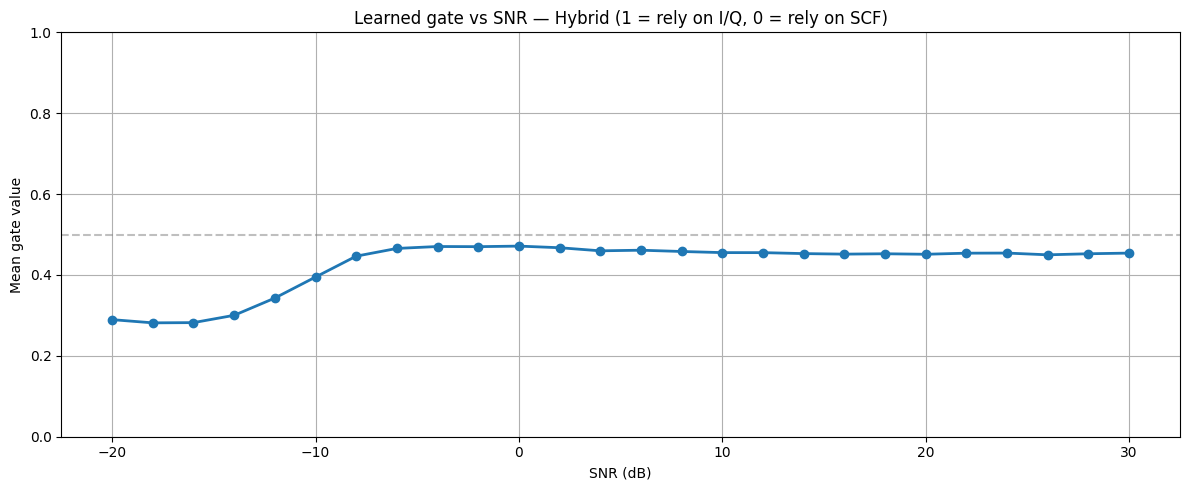

In [ ]:
print("SNR (dB) | Hybrid  | I/Q head | SCF head | Mean gate")
gate_means = []

for snr in snr_range:
    mask = (all_snrs == snr)
    acc_h = (all_preds[mask] == all_labels[mask]).mean()
    acc_i = (all_iq_preds[mask] == all_labels[mask]).mean()
    acc_s = (all_scf_preds[mask] == all_labels[mask]).mean()
    g = all_gate[mask].mean()
    gate_means.append(g)
    print(f"{snr:8d} | {acc_h*100:6.2f}% | {acc_i*100:7.2f}% | {acc_s*100:7.2f}% | {g:.3f}")

plt.figure(figsize = (12, 5))
plt.plot(snr_range, gate_means, marker = 'o', linewidth = 2)
plt.axhline(0.5, color = 'grey', linestyle = '--', alpha = 0.5)
plt.title("Learned gate vs SNR — Hybrid (1 = rely on I/Q, 0 = rely on SCF)")
plt.xlabel("SNR (dB)")
plt.ylabel("Mean gate value")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Saving the eval metrisc if somehow you need
np.savez(os.path.join(save_dir, "hybrid_gated_eval.npz"),
         preds = all_preds,
         labels = all_labels,
         snrs = all_snrs,
         conf = all_conf,
         true_prob = all_true_prob,
         entropy = all_entropy,
         probs = all_probs,
         gate = all_gate,
         iq_preds = all_iq_preds,
         scf_preds = all_scf_preds)

print("Saved.", all_probs.shape)

Saved. (51917, 13)


JUST ADDING SOME STUFF

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

save_dir = "/content/drive/MyDrive/RadioML_Models"
data = np.load(os.path.join(save_dir, "hybrid_gated_eval.npz"))

all_gate = data["gate"]
all_labels = data["labels"]
all_snrs = data["snrs"]

MOD_LABELS = [
    "BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "PAM4", "GFSK",
    "CPFSK", "2FSK", "4FSK", "B-FM", "AM-DSB", "AM-SSB"
]

snr_range = sorted(np.unique(all_snrs).tolist())

print(all_gate.shape, all_labels.shape, all_snrs.shape)    # all (51917,)

Mounted at /content/drive
(51917,) (51917,) (51917,)


In [ ]:
gate_table = []      # 13 rows (classes) x 26 columns (SNRs)

for i in range(13):
    row = []
    for snr in snr_range:
        mask = (all_labels == i) & (all_snrs == snr)
        row.append(all_gate[mask].mean())
    gate_table.append(row)

print("Gate at low SNR (<= -14 dB) and high SNR (>= 20 dB), by class")
print("Class      Low SNR   High SNR")
for i in range(13):
    low_mask = (all_labels == i) & (all_snrs <= -14)
    high_mask = (all_labels == i) & (all_snrs >= 20)
    print(f"{MOD_LABELS[i]:8s}   {all_gate[low_mask].mean():.3f}     {all_gate[high_mask].mean():.3f}")

Gate at low SNR (<= -14 dB) and high SNR (>= 20 dB), by class
Class      Low SNR   High SNR
BPSK       0.324     0.573
QPSK       0.332     0.387
8PSK       0.329     0.992
16QAM      0.327     0.945
64QAM      0.323     0.355
PAM4       0.327     0.353
GFSK       0.236     0.181
CPFSK      0.281     0.399
2FSK       0.275     0.295
4FSK       0.289     0.381
B-FM       0.319     0.330
AM-DSB     0.175     0.313
AM-SSB     0.214     0.381


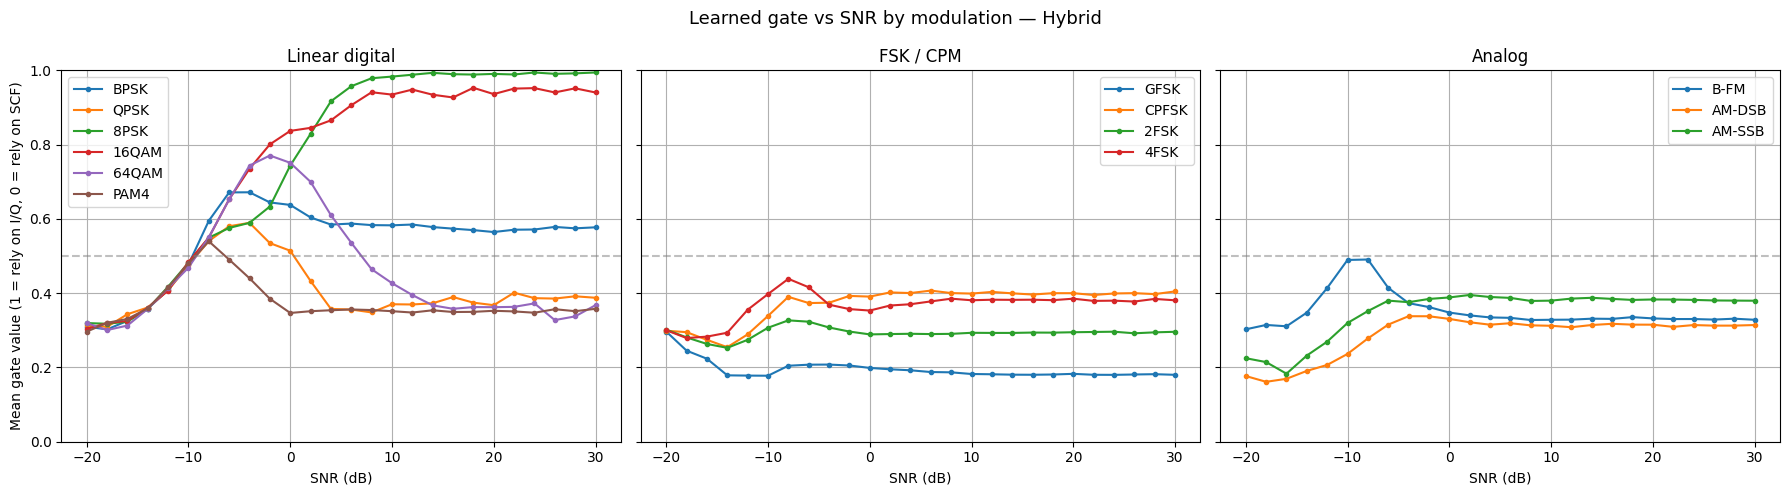

In [ ]:
groups = [
    ("Linear digital", [0, 1, 2, 3, 4, 5]),
    ("FSK / CPM", [6, 7, 8, 9]),
    ("Analog", [10, 11, 12]),
]

fig, axes = plt.subplots(1, 3, figsize = (18, 5), sharey = True)

for g in range(3):
    title = groups[g][0]
    classes = groups[g][1]
    ax = axes[g]

    for i in classes:
        ax.plot(snr_range, gate_table[i], marker = 'o', markersize = 3, linewidth = 1.5, label = MOD_LABELS[i])

    ax.axhline(0.5, color = 'grey', linestyle = '--', alpha = 0.5)
    ax.set_title(title)
    ax.set_xlabel("SNR (dB)")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel("Mean gate value (1 = rely on I/Q, 0 = rely on SCF)")
plt.suptitle("Learned gate vs SNR by modulation — Hybrid", fontsize = 13)
plt.tight_layout()
plt.show()